In [1]:
import re
import os
import math

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from pandas.core.common import random_state
from sqlalchemy import create_engine

# Load variables from .env file
load_dotenv('config.env')

True

In [2]:
db_host = os.getenv("DB_HOST")
db_port = os.getenv("DB_PORT")
db_name = os.getenv("DB_NAME")
db_user = os.getenv("DB_USER")
db_pswd = os.getenv("DB_PSWD")

In [3]:
data_dir = './data'

In [4]:
# Example batch usage
batch_size = 419079
total_records = 419079
num_batches = math.ceil(total_records / batch_size)

# Define your SQLAlchemy connection parameters for `to_sql`
conn_str = f"postgresql+psycopg2://{db_user}:{db_pswd}@{db_host}:{db_port}/{db_name}"
engine = create_engine(conn_str)

In [5]:
def load_batch(limit, offset, conn):
    query = f"""
        SELECT *
        FROM vaers_data
        WHERE json_array_length(symptom_list) > 3
            AND vax_manu NOT IN ('UNKNOWN MANUFACTURER', 'NOVAVAX')
            AND vax_type = 'COVID19'
            AND vax_year <> '2020'
        ORDER BY vaers_id
        LIMIT {limit}
        OFFSET {offset}
    """
    return pd.read_sql(query, con=conn)

In [6]:
vaers_data = load_batch(batch_size, offset=0, conn=engine)
vaers_data.shape

(396563, 10)

In [7]:
vaers_data['vax_year'] = vaers_data['vax_year'].astype(int).astype(str)
vaers_data['num_symptoms'] = vaers_data['symptom_list'].apply(len)
vaers_data['report_length'] = vaers_data['symptom_text'].apply(lambda x: len([y.strip() for y in x.split(' ') if y.strip() != '' ]))

In [8]:
## Divide the reports with less than 30 words into sub-categories for rule based filtering
def sub_30_len_category(report_length):
    if 0 < report_length <= 10:
        return '<=10'
    elif 10 < report_length <= 15:
        return '11-15'
    elif 15 < report_length <= 20:
        return '16-20'
    elif 20 < report_length <= 25:
        return '20-25'
    elif 25 < report_length <= 30:
        return '26-30'
    else:
        return '30+'

vaers_data['sub_30_len_category'] = vaers_data['report_length'].apply(sub_30_len_category)
vaers_data['sub_30_len_category'].value_counts()

sub_30_len_category
30+      288258
<=10      32515
11-15     22672
16-20     19877
20-25     17295
26-30     15946
Name: count, dtype: int64

In [9]:
## Create a copy of vaers_data
vaers_data_copy = vaers_data.copy()

In [10]:
## Data with less than 10 words in the reports
vaers_data[vaers_data['sub_30_len_category'] == '<=10'].head(100)

,vaers_id,vax_type,vax_manu,vax_name,age_yrs,sex,vax_year,year,symptom_text,symptom_list,num_symptoms,report_length,sub_30_len_category
1,916604.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,47.0,F,2021,2021,"Injection site swelling, redness, warm to the ...","[Injection site erythema, Injection site pruri...",4,10,<=10
4,916617.0,COVID19,PFIZER\BIONTECH,COVID19 (COVID19 (PFIZER-BIONTECH)) ...,35.0,F,2021,2021,"Dizziness, chills, fever, muscle aches, pain a...","[Chills, Dizziness, Injection site pain, Myalg...",5,10,<=10
11,916629.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,61.0,M,2021,2021,"Headache, chills, muscle aches and weakness","[Asthenia, Chills, Headache, Myalgia]",4,6,<=10
27,916660.0,COVID19,PFIZER\BIONTECH,COVID19 (COVID19 (PFIZER-BIONTECH)) ...,61.0,F,2021,2021,"Body ache, head ache, fever, nausea, liwer leg...","[Headache, Muscle spasms, Nausea, Pain, Pyrexia]",5,10,<=10
33,916671.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,56.0,F,2021,2021,"Body aches, chills fever lethargy","[Chills, Lethargy, Pain, Pyrexia]",4,5,<=10
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1052,918909.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,20.0,F,2021,2021,"Heart Palpitations, still on going. High feve...","[Chills, Hyperhidrosis, Palpitations, Pyrexia,...",5,10,<=10
1053,918911.0,COVID19,PFIZER\BIONTECH,COVID19 (COVID19 (PFIZER-BIONTECH)) ...,47.0,F,2021,2021,"Temp, diarrhea for 4 hrs, malaise, bad headac...","[Diarrhoea, Headache, Insomnia, Malaise]",4,10,<=10
1068,918939.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,21.0,F,2021,2021,"Low grade fever, chills, head ache, body aches","[Chills, Headache, Pain, Pyrexia]",4,8,<=10
1083,918991.0,COVID19,PFIZER\BIONTECH,COVID19 (COVID19 (PFIZER-BIONTECH)) ...,90.0,M,2021,2021,"Fever(101.8), muscle pain, malaise","[Full blood count, Malaise, Microbiology test,...",5,4,<=10


In [11]:
## Save the data in a file
file_path = os.path.join(data_dir, 'vaers_data_below_10.csv')
vaers_data[vaers_data['sub_30_len_category'] == '<=10'].to_csv(file_path, header=False)

# Remove the records with less than 10 words
vaers_data = vaers_data[~(vaers_data['sub_30_len_category'] == '<=10')]
vaers_data['sub_30_len_category'].value_counts()

sub_30_len_category
30+      288258
11-15     22672
16-20     19877
20-25     17295
26-30     15946
Name: count, dtype: int64

In [14]:
## Apply rule based filtering to the records with report lengths in range (10-30)
# List of temporal words and phrases categorized
plural_temporal_keywords = ['second', 'minute', 'hour', 'day', 'week', 'month', 'year', 'hr', 'min', 'sec']

non_plural_temporal_keywords = [
    'a.m.', 'p.m.', 'am', 'pm',
    'before', 'after', 'later', 'earlier', 'post',
    'spring', 'summer', 'autumn', 'winter',                                                 # Seasonal References
    'morning', 'afternoon', 'evening', 'night', 'midnight', 'noon',                         # parts of day
    'today', 'yesterday', 'tomorrow', 'now', 'then', 'fortnight',                           # Specific Time Points
    'first', 'second', 'third', 'next', 'finally', 'previously', 'initially',               # Ordinals and Sequencers
    'during', 'while', 'until', 'since', 'for', 'brief', 'prolonged', 'lasted',             # Duration Terms
    'monday', 'tuesday', 'wednesday', 'thursday','friday', 'saturday', 'sunday',            # Week Days
    'always', 'often', 'sometimes', 'frequently', 'occasionally', 'yearly', 'daily',        # Frequency Indicators
    'recently', 'soon', 'currently', 'formerly', 'simultaneously', 'lately', 'suddenly', 'gradually',     # Time-Related Adverbs
    'january', 'february', 'march', 'april', 'may', 'june', 'july', 'august', 'september', 'october', 'november', 'december',
    'jan', 'feb', 'mar', 'apr', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec'
]

# Regex pattern to match dates in the format MM/DD/YYYY or DD/MM or MM/YYYY
date_pattern = r'\b(\d{1,2}/\d{1,2}(?:/\d{2,4})?|\d{1,2}/\d{4})\b'

# Regex pattern to match time in the format HH:MM
time_pattern = r'\b([01]?[0-9]|2[0-3]):([0-5]?[0-9])\b'

# Combine into a single pattern with proper escaping and boundaries
pattern = (
        r'\b(' + '|'.join([f'{re.escape(word)}s?' for word in plural_temporal_keywords]
                          + [re.escape(word) for word in non_plural_temporal_keywords])
        + r')\b|' + date_pattern + r'|' + time_pattern
)

# Apply the regex pattern to filter rows
vaers_data['has_temporal_info'] = vaers_data['symptom_text'].str.contains(pattern, flags=re.IGNORECASE)

/var/folders/k4/zx_j67kd21n6d03ptwmp8_vm0000gn/T/ipykernel_94271/2736613031.py:34: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  vaers_data['has_temporal_info'] = vaers_data['symptom_text'].str.contains(pattern, flags=re.IGNORECASE)


In [15]:
vaers_data.groupby(['has_temporal_info', 'sub_30_len_category'])['vaers_id'].count()

has_temporal_info  sub_30_len_category
False              11-15                   14439
                   16-20                    8059
                   20-25                    4384
                   26-30                    2635
                   30+                      5060
True               11-15                    8233
                   16-20                   11818
                   20-25                   12911
                   26-30                   13311
                   30+                    283198
Name: vaers_id, dtype: int64

In [16]:
# Save the data for manual analysis
vaers_data[(
        (~vaers_data['has_temporal_info']) &
        (vaers_data['sub_30_len_category'].isin(['11-15', '16-20', '21-25', '26-30']))
)].to_csv(os.path.join(data_dir, 'reports_without_temporal_cues_<30.csv'), index=False)

vaers_data[(
        (~vaers_data['has_temporal_info']) &
        (vaers_data['sub_30_len_category'] == '30+')
)].to_csv(os.path.join(data_dir, 'reports_without_temporal_cues_30+.csv'), index=False)

In [17]:
## Filter the records with more than 30 words or with temporal cues
vaers_data = vaers_data[(
    (vaers_data['has_temporal_info']) |
    (vaers_data['sub_30_len_category'] == '30+')
)]

In [18]:
vaers_data.groupby('sub_30_len_category')['vaers_id'].count()

sub_30_len_category
11-15      8233
16-20     11818
20-25     12911
26-30     13311
30+      288258
Name: vaers_id, dtype: int64

In [19]:
vaers_data.head(100)

,vaers_id,vax_type,vax_manu,vax_name,age_yrs,sex,vax_year,year,symptom_text,symptom_list,num_symptoms,report_length,sub_30_len_category,has_temporal_info
0,916602.0,COVID19,PFIZER\BIONTECH,COVID19 (COVID19 (PFIZER-BIONTECH)) ...,23.0,F,2021,2021,"About 15 minutes after receiving the vaccine, ...","[Chest discomfort, Dysphagia, Pain in extremit...",4,73,30+,True
2,916611.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,33.0,F,2021,2021,12pm Received shot 1 pm Sore arm at injection ...,"[Blood pressure decreased, Chest pain, Chills,...",20,140,30+,True
5,916620.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,65.0,M,2021,2021,1. Sore arm started several hours later appro...,"[Arthralgia, Chills, Headache, Mobility decrea...",8,69,30+,True
6,916621.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,25.0,F,2021,2021,Fatigue - 2 hours prior. Muscle aches/pain - 3...,"[Chills, Fatigue, Headache, Myalgia]",4,26,26-30,True
7,916622.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,22.0,F,2021,2021,Felt a little nauseous and a little headache s...,"[Headache, Heart rate increased, Injection sit...",6,131,30+,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
126,916840.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,32.0,F,2021,2021,"Fatigue, headaches, muscle aches with 12 hours...","[Fatigue, Headache, Injection site pain, Myalg...",5,44,30+,True
127,916842.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,29.0,F,2021,2021,"Fever, chills, body aches. Swelling at site f...","[Chills, Injection site swelling, Lymphadenopa...",5,13,11-15,True
128,916844.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,55.0,F,2021,2021,Apart from a very sore arm about 24 hours afte...,"[Burning sensation, Injection site erythema, I...",4,43,30+,True
130,916848.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,34.0,F,2021,2021,approx. 6 hours post shot felt like throat was...,"[Hypoaesthesia oral, Paraesthesia, Paraesthesi...",4,25,20-25,True


In [20]:
# Create the categorized length column with ranges in the labels
bins = [0, 30, 100, 200, 500, 1000, np.inf]
labels = ['Very Short', 'Short', 'Medium', 'Long', 'Very Long', 'Extremely Long']
vaers_data['length_category'] = pd.cut(vaers_data['report_length'], bins=bins, labels=labels)

/var/folders/k4/zx_j67kd21n6d03ptwmp8_vm0000gn/T/ipykernel_94271/1363307417.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  vaers_data['length_category'] = pd.cut(vaers_data['report_length'], bins=bins, labels=labels)


In [21]:
vaers_data.head()

,vaers_id,vax_type,vax_manu,vax_name,age_yrs,sex,vax_year,year,symptom_text,symptom_list,num_symptoms,report_length,sub_30_len_category,has_temporal_info,length_category
0,916602.0,COVID19,PFIZER\BIONTECH,COVID19 (COVID19 (PFIZER-BIONTECH)) ...,23.0,F,2021,2021,"About 15 minutes after receiving the vaccine, ...","[Chest discomfort, Dysphagia, Pain in extremit...",4,73,30+,True,Short
2,916611.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,33.0,F,2021,2021,12pm Received shot 1 pm Sore arm at injection ...,"[Blood pressure decreased, Chest pain, Chills,...",20,140,30+,True,Medium
5,916620.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,65.0,M,2021,2021,1. Sore arm started several hours later appro...,"[Arthralgia, Chills, Headache, Mobility decrea...",8,69,30+,True,Short
6,916621.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,25.0,F,2021,2021,Fatigue - 2 hours prior. Muscle aches/pain - 3...,"[Chills, Fatigue, Headache, Myalgia]",4,26,26-30,True,Very Short
7,916622.0,COVID19,MODERNA,COVID19 (COVID19 (MODERNA)) ...,22.0,F,2021,2021,Felt a little nauseous and a little headache s...,"[Headache, Heart rate increased, Injection sit...",6,131,30+,True,Medium


/var/folders/k4/zx_j67kd21n6d03ptwmp8_vm0000gn/T/ipykernel_94271/2452695411.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  vaers_data['num_symptom_str'] = vaers_data['num_symptoms'].apply(lambda x: '10+' if x > 10 else str(x))


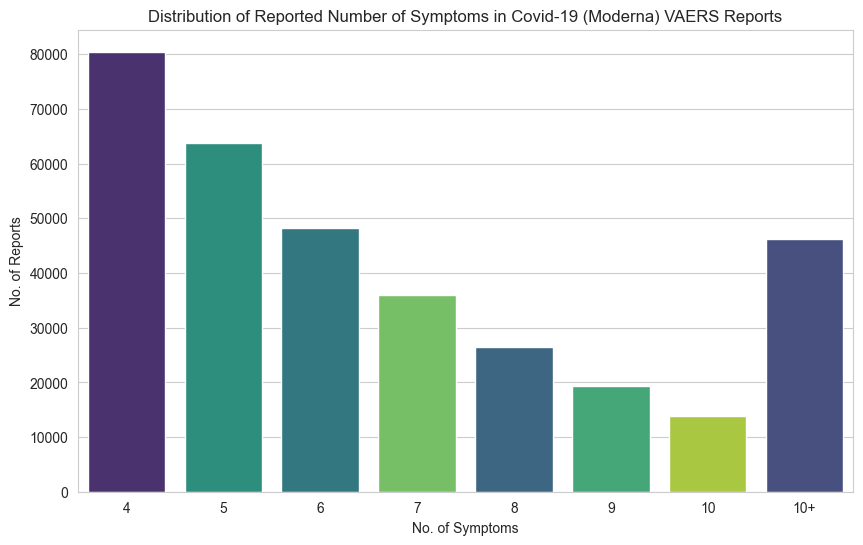

In [22]:
vaers_data['num_symptom_str'] = vaers_data['num_symptoms'].apply(lambda x: '10+' if x > 10 else str(x))

# Define the correct order for the x-axis labels, including '10+' at the end
order = [str(i) for i in range(4, 11)] + ['10+']

# Plotting the bar chart
plt.figure(figsize=(10, 6))
sns.countplot(data=vaers_data, x='num_symptom_str', palette="viridis", order=order, hue='num_symptom_str', legend=False)

# Adding labels and title
plt.xlabel("No. of Symptoms")
plt.ylabel("No. of Reports")
plt.title("Distribution of Reported Number of Symptoms in Covid-19 (Moderna) VAERS Reports")
plt.xticks(rotation=0)
plt.show()

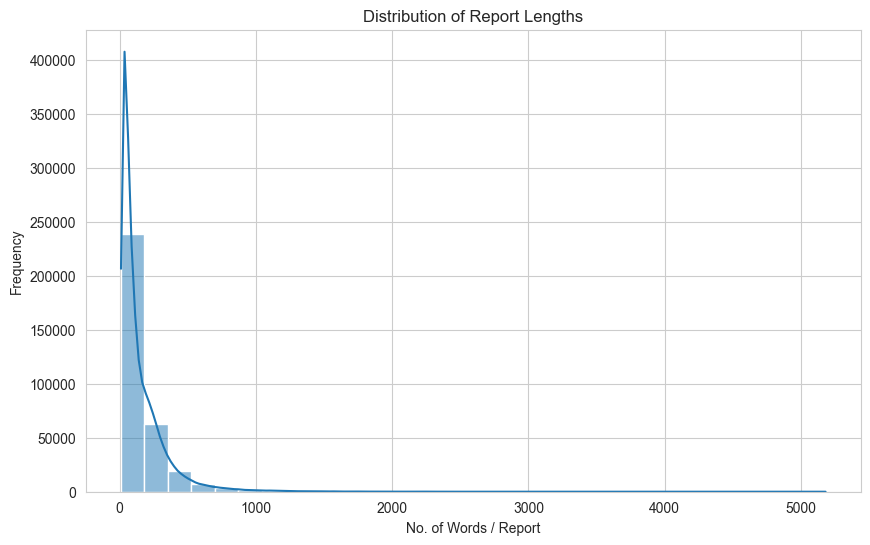

In [23]:
## Histogram of Report Lengths
plt.figure(figsize=(10, 6))
sns.histplot(vaers_data['report_length'], bins=30, kde=True)
plt.xlabel("No. of Words / Report")
plt.ylabel("Frequency")
plt.title("Distribution of Report Lengths")
plt.show()

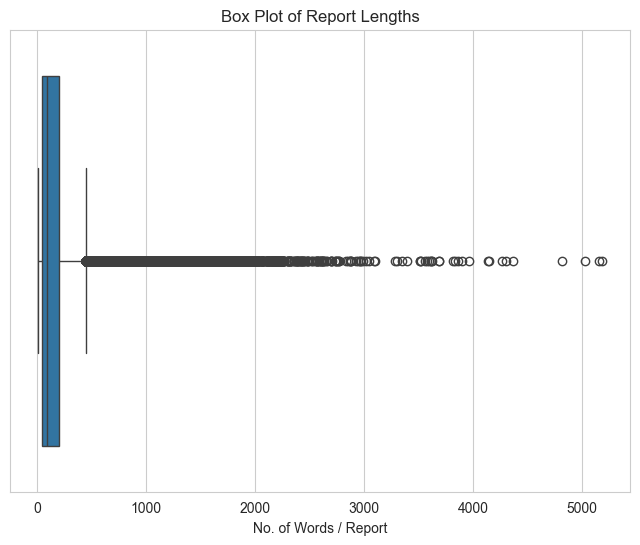

In [24]:
# Box Plot of Report Lengths
plt.figure(figsize=(8, 6))
sns.boxplot(x=vaers_data['report_length'])
plt.xlabel("No. of Words / Report")
plt.title("Box Plot of Report Lengths")
plt.show()

/var/folders/k4/zx_j67kd21n6d03ptwmp8_vm0000gn/T/ipykernel_94271/553365795.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  bar_plot.set_xticklabels(custom_labels)


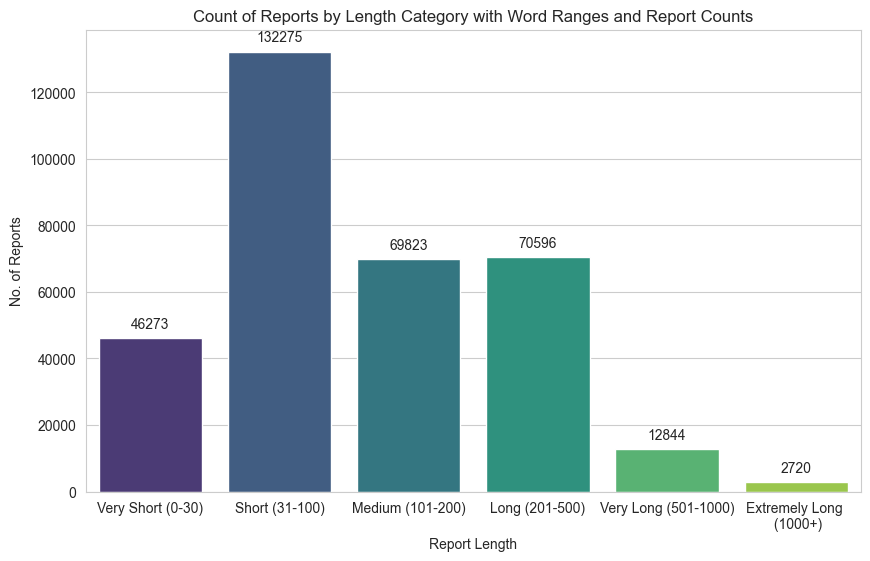

In [25]:
plt.figure(figsize=(10, 6))
bar_plot = sns.countplot(
    data=vaers_data,
    x='length_category',
    palette='viridis',
    legend=False,
    hue='length_category'
)

# Set custom x-axis labels including word ranges
custom_labels = [
    'Very Short (0-30)',
    'Short (31-100)',
    'Medium (101-200)',
    'Long (201-500)',
    'Very Long (501-1000)',
    'Extremely Long \n (1000+)'
]
bar_plot.set_xticklabels(custom_labels)

# Adding annotations on top of each bar with the total number of reports
category_counts = vaers_data['length_category'].value_counts(sort=False).values
for p, count in zip(bar_plot.patches, category_counts):
    bar_plot.annotate(f'{int(count)}',
                      (p.get_x() + p.get_width() / 2., p.get_height()),  # Position at center of each bar
                      ha='center', va='bottom',  # Center alignment
                      xytext=(0, 5), textcoords='offset points')  # Offset by 5 points above bar

# Adding labels and title
plt.xlabel("Report Length")
plt.ylabel("No. of Reports")
plt.title("Count of Reports by Length Category with Word Ranges and Report Counts")
plt.show()

## Sampling Data:

In [26]:
## Create separate dataframes for each vaccine
pfizer_data = vaers_data[vaers_data['vax_manu'].str.strip() == 'PFIZER\BIONTECH']
moderna_data = vaers_data[vaers_data['vax_manu'].str.strip() == 'MODERNA']
janssen_data = vaers_data[vaers_data['vax_manu'].str.strip() == 'JANSSEN']

In [27]:
random_state = 42
vac_sample_size = 5000
sampling_vars = ['length_category','vax_year']

pfizer_frac = 5050/pfizer_data.shape[0]
moderna_frac = 5050/moderna_data.shape[0]
janssen_frac = 5050/janssen_data.shape[0]

In [28]:
## Sample 3000 records for each vaccine
s_pfizer_data = pfizer_data.groupby(
    sampling_vars, group_keys=False
).apply(lambda x: x.sample(frac=pfizer_frac, random_state=random_state), include_groups=True)
fs_pfizer_data = s_pfizer_data.sample(n=vac_sample_size, random_state=random_state)

s_moderna_data = moderna_data.groupby(
    sampling_vars, group_keys=False
).apply(lambda x: x.sample(frac=moderna_frac, random_state=random_state), include_groups=True)
fs_moderna_data = s_moderna_data.sample(n=vac_sample_size, random_state=random_state)

s_janssen_data = janssen_data.groupby(
    sampling_vars, group_keys=False
).apply(lambda x: x.sample(frac=janssen_frac, random_state=random_state), include_groups=True)
fs_janssen_data = s_janssen_data.sample(n=vac_sample_size, random_state=random_state)

/var/folders/k4/zx_j67kd21n6d03ptwmp8_vm0000gn/T/ipykernel_94271/2565739803.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  s_pfizer_data = pfizer_data.groupby(
/var/folders/k4/zx_j67kd21n6d03ptwmp8_vm0000gn/T/ipykernel_94271/2565739803.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  s_pfizer_data = pfizer_data.groupby(
/var/folders/k4/zx_j67kd21n6d03ptwmp8_vm0000gn/T/ipykernel_94271/2565739803.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future ve

In [29]:
sampled_data = pd.concat([fs_pfizer_data, fs_moderna_data, fs_janssen_data], ignore_index=True)

In [30]:
sampled_data.vax_manu.value_counts()

vax_manu
PFIZER\BIONTECH                             5000
MODERNA                                     5000
JANSSEN                                     5000
Name: count, dtype: int64

In [31]:
sampled_data = sampled_data[[
    'vaers_id', 'vax_type', 'vax_manu', 'age_yrs', 'sex', 'vax_year', 'symptom_text',
    'symptom_list', 'num_symptoms', 'report_length', 'length_category'
]]

In [32]:
sampled_data.head()

,vaers_id,vax_type,vax_manu,age_yrs,sex,vax_year,symptom_text,symptom_list,num_symptoms,report_length,length_category
0,2614552.0,COVID19,PFIZER\BIONTECH,73.0,F,2023,ACUTE NON ST ELEVATION MI 7/26/2021 DM 2 W ULC...,"[Acute myocardial infarction, Cerebrovascular ...",9,231,Long
1,1641686.0,COVID19,PFIZER\BIONTECH,47.0,F,2021,On 04/02/2021 that night it began with headach...,"[Abdominal discomfort, Acoustic stimulation te...",12,77,Short
2,1091525.0,COVID19,PFIZER\BIONTECH,39.0,M,2021,No adverse reactions for over an hour. Acute ...,"[Bone pain, Chills, Influenza like illness, Le...",4,22,Very Short
3,2236505.0,COVID19,PFIZER\BIONTECH,69.0,F,2022,Breakthrough COVID case: When I woke up in the...,"[COVID-19, Cough, Decreased appetite, Orophary...",9,129,Medium
4,2683510.0,COVID19,PFIZER\BIONTECH,41.0,F,2023,"She got her vaccine, she was alright, arm was ...","[Atrioventricular block, Cyanosis, Discomfort,...",10,232,Long


In [33]:
file_path = os.path.join(data_dir, 'sampled_data.csv')
sampled_data.to_csv(file_path, index=False)

In [333]:
pfizer_data.groupby(['length_category', 'vax_year']).count()['vaers_id'] / pfizer_data.shape[0] * 100

/var/folders/k4/zx_j67kd21n6d03ptwmp8_vm0000gn/T/ipykernel_7932/1784706039.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pfizer_data.groupby(['length_category', 'vax_year']).count()['vaers_id'] / pfizer_data.shape[0] * 100


length_category  vax_year
Very Short       2021        10.075856
                 2022         1.833681
                 2023         0.504363
                 2024         0.171027
Short            2021        28.468333
                 2022         7.300518
                 2023         1.488273
                 2024         0.525825
Medium           2021        15.465563
                 2022         3.846438
                 2023         0.635148
                 2024         0.258888
Long             2021        17.289184
                 2022         4.814922
                 2023         0.780689
                 2024         0.380284
Very Long        2021         3.033555
                 2022         1.429922
                 2023         0.306508
                 2024         0.134139
Extremely Long   2021         0.682768
                 2022         0.390345
                 2023         0.122067
                 2024         0.061704
Name: vaers_id, dtype: float64

In [34]:
fs_pfizer_data.groupby(['length_category', 'vax_year']).count()['vaers_id'] / fs_pfizer_data.shape[0] * 100

/var/folders/k4/zx_j67kd21n6d03ptwmp8_vm0000gn/T/ipykernel_94271/1544963066.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fs_pfizer_data.groupby(['length_category', 'vax_year']).count()['vaers_id'] / fs_pfizer_data.shape[0] * 100


length_category  vax_year
Very Short       2021        10.08
                 2022         1.84
                 2023         0.50
                 2024         0.18
Short            2021        28.44
                 2022         7.30
                 2023         1.50
                 2024         0.54
Medium           2021        15.36
                 2022         3.84
                 2023         0.64
                 2024         0.24
Long             2021        17.38
                 2022         4.82
                 2023         0.78
                 2024         0.38
Very Long        2021         3.04
                 2022         1.44
                 2023         0.30
                 2024         0.14
Extremely Long   2021         0.68
                 2022         0.40
                 2023         0.12
                 2024         0.06
Name: vaers_id, dtype: float64